# Analytic p=1 correlations and RQAOA

**Version 0.1.0rc2.** The notebook verifies the analytic evaluator for the mean
cut and the physical ZZ correlations for a single QAOA layer. No `2**N` state
vector is created. The source plugs into the same `RQAOACPU` used in notebook 04;
the recursive coordinator and the exact reducer are not replaced.

Supported: weighted Max-Cut without fields, the standard `|+>` state, an X mixer,
`p=1` and the Mean Cut criterion. The full distribution, shots, CVaR, Gibbs,
Best-of-K and Threshold Probability are not supported by this source.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from copy import deepcopy
from itertools import combinations
import json
import math
import time

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

import QA_max_cut_lib as qa
from QA_max_cut_lib import (
    AnalyticP1Evaluator, AnalyticP1CorrelationSource, ExactCPU,
    GraphReducer, SolverFactory, WeightedGraph, tools,
)
from QA_max_cut_lib.core.budget import ShotBudget
from QA_max_cut_lib.solvers.qaoa_state import cut_diagonal, state_at_angles

root = Path.cwd()
if not (root / 'configs').is_dir():
    root = root.parent
assert (root / 'configs').is_dir(), 'Open the notebook from the project or notebooks folder.'
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
output_dir = root / 'notebooks' / '_outputs' / ('analytic_p1_' + stamp)
output_dir.mkdir(parents=True, exist_ok=True)
print('QA_max_cut_lib', qa.__version__)
print('Output:', output_dir)


QA_max_cut_lib 0.1.0a4
Output: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\notebooks\_outputs\analytic_p1_20261102T133929Z_4ceec4


## 1. Formula and signs

For `E=-C` and `J=w/2` the correlation reads

$$c_{uv}=\frac12\sin(\gamma w_{uv})(P_{u\setminus v}+P_{v\setminus u})\sin(4\beta)
+\frac12(P^-_{uv}-P^+_{uv})\sin^2(2\beta).$$

The first term is positive for a positive weight and a positive
`sin(gamma*w)`. For a single edge at `gamma=pi/(2|w|)` and `beta=-pi/8` it gives
`c=-sign(w)`. For a non-adjacent pair `w=0`, but common neighbours can make the
second term non-zero.

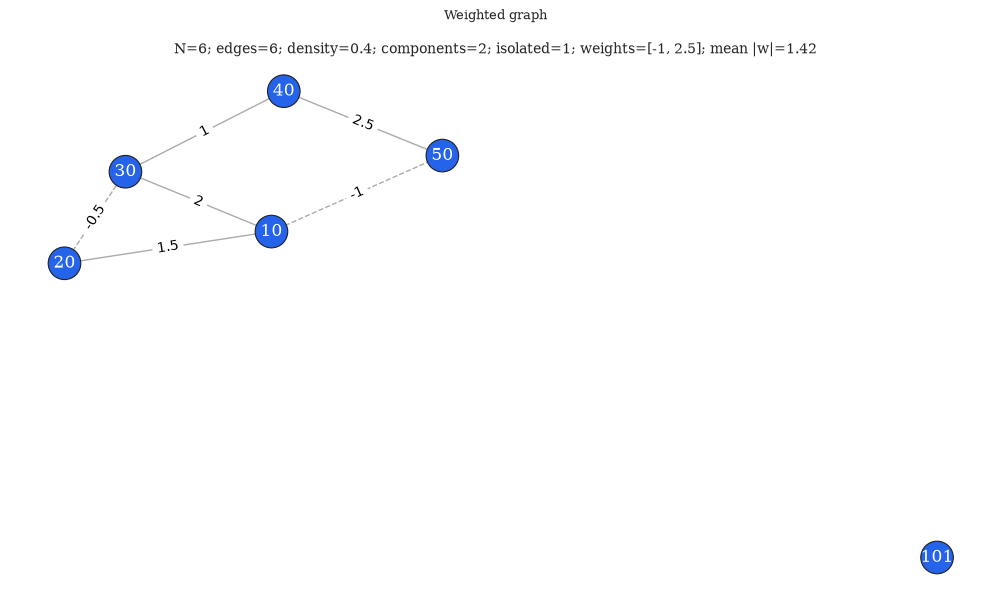

Exact cut: 6.0


In [2]:
graph = WeightedGraph(
    [(10, 20, 1.5), (20, 30, -0.5), (10, 30, 2.0),
     (30, 40, 1.0), (40, 50, 2.5), (10, 50, -1.0)],
    nodes=[10, 20, 30, 40, 50, 101],
)
reference = ExactCPU()
reference.solve(graph, report=0, logs=0)
figure = tools.plot_graph_info(graph, {'style': {'text_engine': 'mathtext', 'figsize': [10, 6]}})
display(figure)
plt.close(figure)
print('Exact cut:', reference.cut_value)


## 2. Independent check at fixed angles

We compare the analytic correlations with the full state vector of the same
package. This checks the formula, not the optimizer: the angles are set by hand.

In [3]:
evaluator = AnalyticP1Evaluator(graph, pair_batch_size=3)
gamma_test, beta_test = 0.37, -0.61
probabilities = state_at_angles(cut_diagonal(graph), [gamma_test, beta_test], 1)[1]
n = len(graph)
indices = np.arange(1 << n, dtype=np.uint64)
bits = ((indices[:, None] >> np.arange(n, dtype=np.uint64)[None, :]) & np.uint64(1)).astype(float)
signs = 1.0 - 2.0 * bits
state_matrix = (signs * probabilities[:, None]).T @ signs
analytic_values = evaluator.correlations(gamma_test, beta_test, pair_domain='all_pairs')
error = max(
    abs(value - state_matrix[evaluator.node_order.index(u), evaluator.node_order.index(v)])
    for (u, v), value in analytic_values.items()
)
print('All pairs:', len(analytic_values))
print('Max correlation error:', error)
print('Analytic mean energy:', evaluator.expected_energy(gamma_test, beta_test))
print('Statevector mean energy:', float(-(cut_diagonal(graph) @ probabilities)))
assert error < 1e-12
assert math.isclose(
    evaluator.expected_energy(gamma_test, beta_test),
    float(-(cut_diagonal(graph) @ probabilities)),
    abs_tol=1e-12,
)


All pairs: 15
Max correlation error: 1.6653345369377348e-16
Analytic mean energy: -4.3316068353666415
Statevector mean energy: -4.331606835366642


## 3. One edge and a non-adjacent pair

A single edge checks the phase sign and the constraints. The path `u-k-v` shows
that a zero weight does not mean a zero correlation: at `gamma=pi/2`, `beta=pi/4`
the shared neighbour gives `c_uv=1`.

In [4]:
for weight in (0.5, 1.0, -2.0):
    edge_graph = WeightedGraph([(0, 1, weight)], nodes=[0, 1])
    edge_eval = AnalyticP1Evaluator(edge_graph)
    value = edge_eval.correlations(math.pi / (2 * abs(weight)), -math.pi / 8)[(0, 1)]
    print('w=', weight, 'c=', value, 'E=', edge_eval.expected_energy(
        math.pi / (2 * abs(weight)), -math.pi / 8))
    assert math.isclose(value, -math.copysign(1.0, weight), abs_tol=1e-12)

path_graph = WeightedGraph([(0, 1, 1.0), (1, 2, 1.0)], nodes=[0, 1, 2])
path_eval = AnalyticP1Evaluator(path_graph)
path_c = path_eval.correlations(math.pi / 2, math.pi / 4, pair_domain='all_pairs')[(0, 2)]
print('Nonedge c(0,2):', path_c)
assert math.isclose(path_c, 1.0, abs_tol=1e-12)


w= 0.5 c= -1.0 E= -0.5
w= 1.0 c= -1.0 E= -1.0
w= -2.0 c= 1.0 E= 0.0
Nonedge c(0,2): 1.0


## 4. Exact minimization over beta

`E(gamma,beta)=F0+Fs sin(4beta)+Fc cos(4beta)`, so the minimum is
`F0-hypot(Fs,Fc)`, and `beta_*` follows from `atan2`. We compare with a dense
beta grid; the grid must not produce a lower energy.

In [5]:
profile = evaluator.energy_min_beta(0.7)
beta_grid = np.linspace(-math.pi / 2, math.pi / 2, 801)
grid_energies = [evaluator.expected_energy(0.7, float(beta)) for beta in beta_grid]
print('beta*:', profile['beta_star'])
print('F0, Fs, Fc, R:', profile['F0'], profile['Fs'], profile['Fc'], profile['R'])
print('minimum:', profile['energy_min'])
print('dense-grid minimum:', min(grid_energies))
assert min(grid_energies) >= profile['energy_min'] - 1e-12
assert math.isclose(
    evaluator.expected_energy(0.7, profile['beta_star']),
    profile['energy_min'],
    abs_tol=1e-12,
)


beta*: 1.1422321098688533
F0, Fs, Fc, R: -3.0156391277863723 1.838932533800135 0.2656391277863722 1.8580196473879627
minimum: -4.873658775174335
dense-grid minimum: -4.873654721549084


## 5. Gamma search and the correlation source

The source scans an explicit gamma grid, eliminates beta at every point and
returns correlations only at the selected angles. No shots are consumed.

In [6]:
source_config = tools.load_json(root / 'configs/solvers/rqaoa_analytic_p1_cpu.json')['correlation_source']
source_config['optimizer']['parameters']['points'] = 21
state = GraphReducer().start(graph)
source = AnalyticP1CorrelationSource(source_config)
source_result = source.estimate(state, budget=ShotBudget(0), pair_domain='all_pairs')
print('Angles:', source_result.angles)
print('Covered pairs:', len(source_result.values))
print('Profile points:', len(source_result.training['gamma_profile']['gamma_values']))
print('Resources:', source_result.resources)
assert source_result.resources['training_shots'] == 0
assert source_result.resources['correlation_shots'] == 0
assert len(source_result.values) == len(list(combinations(sorted(graph.nodes), 2)))


Angles: [-0.62831853  0.42260357]
Covered pairs: 15
Profile points: 21
Resources: {'training_shots': 0, 'correlation_shots': 0, 'readout_shots': 0, 'objective_evaluations': 0, 'optimizer_steps': 0, 'source_calls': 1, 'gamma_points': 21, 'coefficient_passes': 21, 'pair_correlators': 15, 'classical_seconds': 0.002144699916243553}


## 6. RQAOA with the analytic source

Only the source configuration changes. The `RQAOACPU` loop, the exact reducer,
the exact remainder and the reconstruction stay the same. The total shot limit
is zero.

In [7]:
config = tools.load_json(root / 'configs/solvers/rqaoa_analytic_p1_cpu.json')
config.pop('save', None)
config['parameters'] = {'finish_at': 3, 'max_reductions': None}
config['correlation_source']['optimizer']['parameters']['points'] = 21
config['output'] = {'report': 0, 'logs': 0, 'color': 'never'}
algorithm = SolverFactory.from_config(config)
solution = algorithm.solve(graph)
print('Solution:', solution)
print('Cut:', algorithm.cut_value, 'Energy:', algorithm.solution_energy)
print('Reductions:', algorithm.reductions_completed, 'Source:', algorithm.solution_source)
print('Shots:', algorithm.resources['shots_used'])
print('Resources:', algorithm.resources)
assert set(solution) == set(graph.nodes)
assert algorithm.resources['shots_used'] == 0
assert math.isclose(algorithm.cut_value, graph.cut_value(solution), abs_tol=1e-12)
assert math.isclose(algorithm.solution_energy, -algorithm.cut_value, abs_tol=1e-12)
assert math.isclose(algorithm.cut_value, algorithm.cut_offset + algorithm.reduced_cut_value)


Solution: {10: 1, 40: 1, 101: 1, 30: -1, 20: -1, 50: -1}
Cut: 6.0 Energy: -6.0
Reductions: 3 Source: zero_interaction_residual
Shots: 0
Resources: {'shots_used': 0, 'training_shots': 0, 'correlation_shots': 0, 'readout_shots': 0, 'objective_evaluations': 0, 'optimizer_steps': 0, 'source_attempts': 3, 'source_calls': 3, 'reductions_completed': 3, 'num_stages': 4, 'num_treads': 1, 'gamma_points': 63, 'coefficient_passes': 63, 'pair_correlators': 14, 'classical_seconds': 0.009400099981576204}


## 7. Reduction table and gamma profile

The profile row refers to the graph before the corresponding merge. `A`, `B` and
`E0` are the coefficients of the analytic energy; `gamma_profile` is not an ADAM
history.

,step,removed,retained,sign,weight,correlation,fixed_energy,expected_fixed_energy,cut_offset,ising_constant
0,1,50,40,-1,2.5,-0.803236,-2.5,-2.254045,1.5,-4.00
1,2,20,10,-1,1.5,-0.598394,-1.5,-1.198795,2.5,-4.75
2,3,30,10,-1,2.5,-1.000000,-2.5,-2.500000,6.0,-6.00


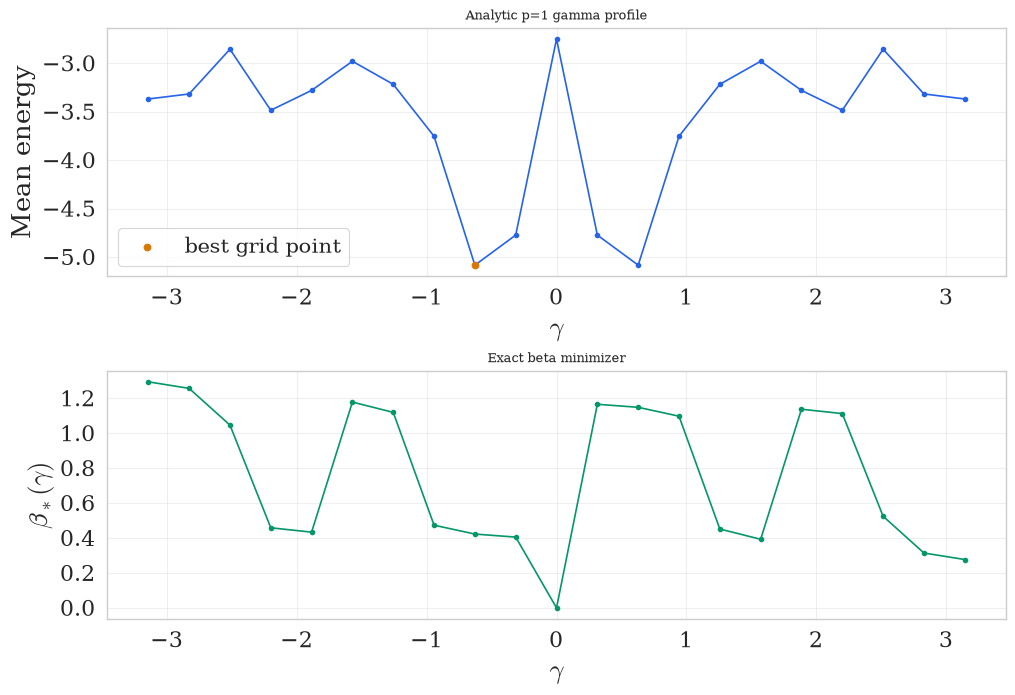

In [8]:
rows = []
for event in algorithm.reduction_history:
    rows.append({
        'step': event['step'],
        'removed': event['removed_node'],
        'retained': event['retained_node'],
        'sign': event['sign'],
        'weight': event['selected_weight'],
        'correlation': event['physical_correlation'],
        'fixed_energy': event['fixed_energy'],
        'expected_fixed_energy': event['expected_fixed_energy'],
        'cut_offset': event['cut_offset'],
        'ising_constant': event['ising_constant'],
    })
from pandas import DataFrame
display(DataFrame(rows))

profile_figure = tools.plot_analytic_gamma_profile(algorithm, {
    'selection': {'reduction_step': 1},
    'style': {'text_engine': 'mathtext', 'figsize': [10, 7]},
})
display(profile_figure)
plt.close(profile_figure)


## 8. Existing plots and standalone HTML

Energies, weights and trajectories are read from the same record. Plotting does
not run the gamma scanner and does not consume shots.

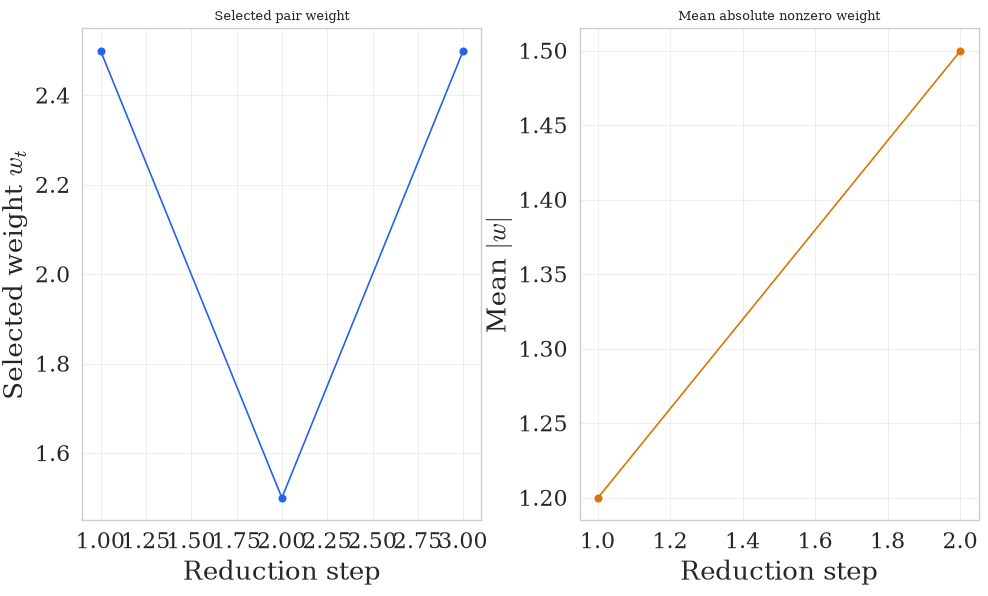

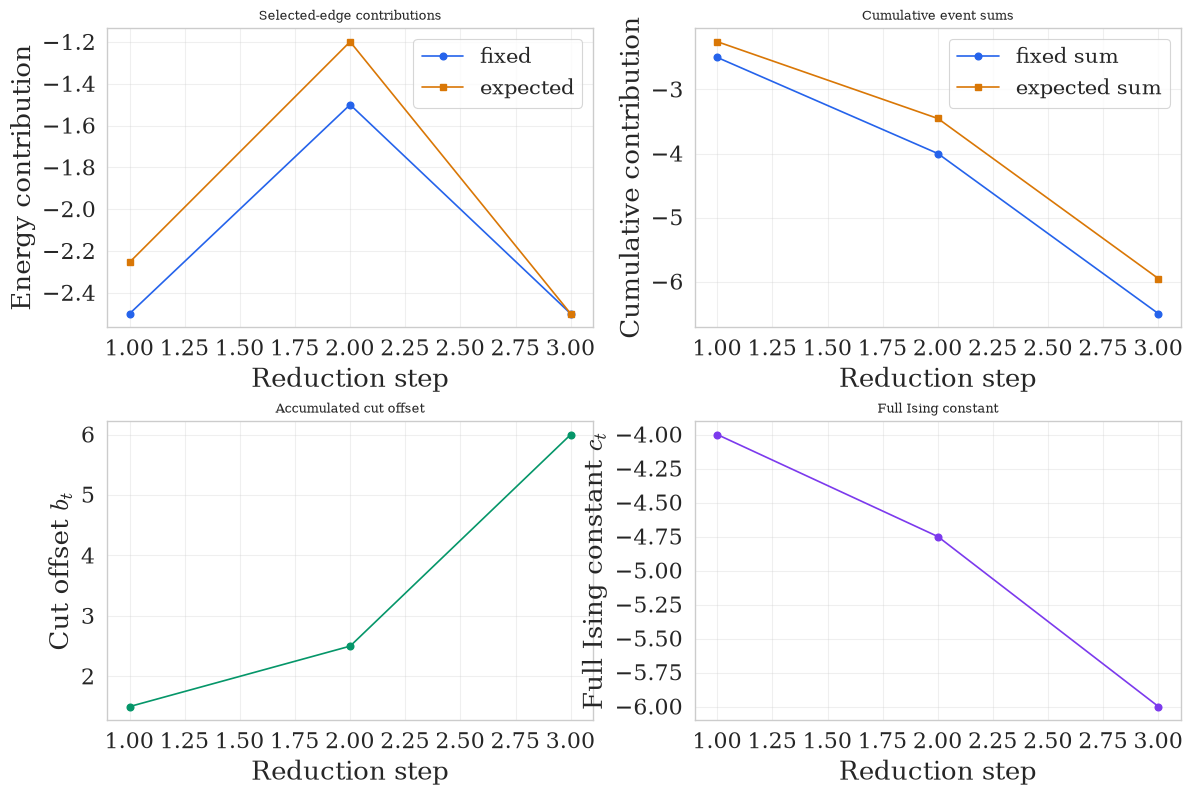

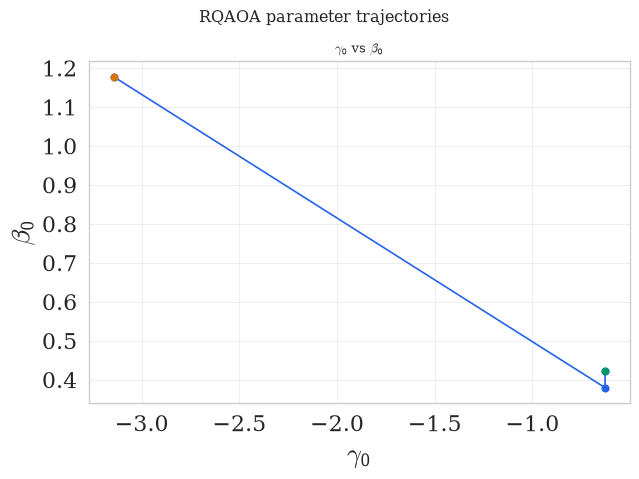

3D traces: 1
HTML: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\notebooks\_outputs\analytic_p1_20261102T133929Z_4ceec4\analytic_trajectories\analytic_trajectories.html


In [9]:
weights_figure = tools.plot_reduction_weights(algorithm, {'style': {'text_engine': 'mathtext', 'figsize': [10, 6]}})
display(weights_figure)
plt.close(weights_figure)
energy_figure = tools.plot_reduction_energy(algorithm, {'style': {'text_engine': 'mathtext', 'figsize': [12, 8]}})
display(energy_figure)
plt.close(energy_figure)
trajectory_figure = tools.plot_parameter_trajectories(algorithm, {'style': {'text_engine': 'mathtext', 'figsize': [8, 6]}})
display(trajectory_figure)
plt.close(trajectory_figure)
trajectory_3d = tools.plot_parameter_trajectories_3d(algorithm, {
    'save': {
        'path': str(output_dir),
        'filename': 'analytic_trajectories',
        'format': 'html',
        'makedir': True,
        'savedir': True,
        'metadata': True,
    }
})
print('3D traces:', len(trajectory_3d.data))
print('HTML:', trajectory_3d.layout.meta['qa_primary'])


## 9. Saving and re-analysis

The root JSON is saved with the selected attributes. The profile is part of
`local_optimizer_history`; once loaded it can be plotted without recomputation.

Saved: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\notebooks\_outputs\analytic_p1_20261102T133929Z_4ceec4\saved\analytic_rqaoa\analytic_rqaoa.json


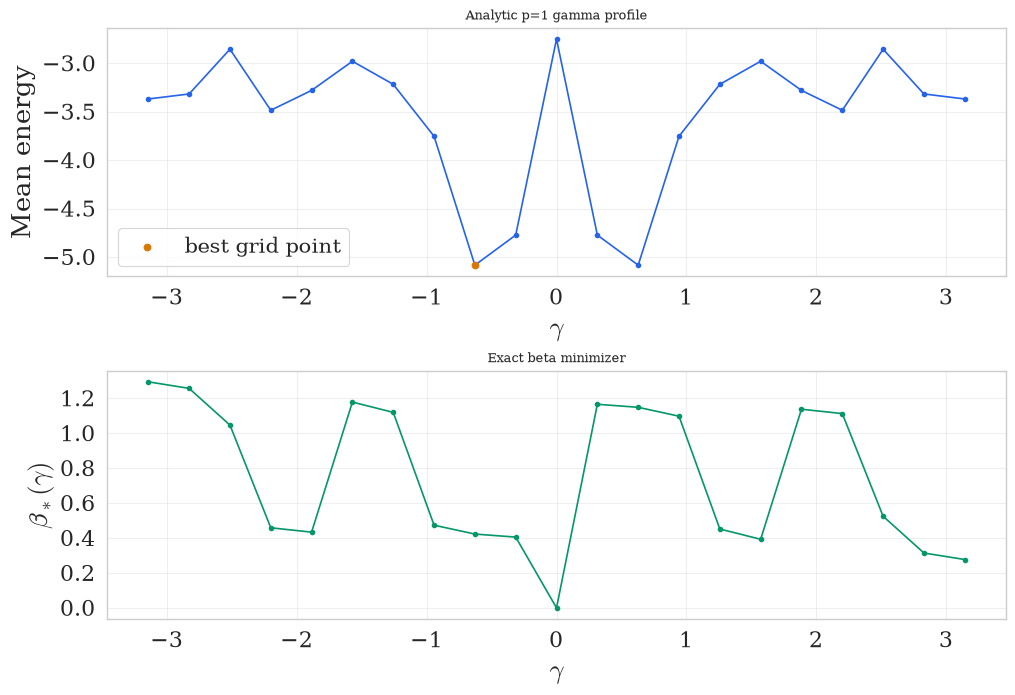

In [10]:
files = tools.save_result(algorithm, {
    'path': str(output_dir / 'saved'),
    'filename': 'analytic_rqaoa',
    'atts': ['solution', 'cut_value', 'cut_offset', 'ising_constant',
             'reduction_history', 'parameter_trajectory', 'local_optimizer_history'],
    'savedir': True,
    'makedir': True,
})
loaded = tools.load_result(files.primary)
print('Saved:', files.primary)
assert loaded.solution == algorithm.solution
assert loaded.local_optimizer_history[0]['profile_type'] == 'analytic_gamma_grid'
loaded_figure = tools.plot_analytic_gamma_profile(loaded, {
    'style': {'text_engine': 'mathtext', 'figsize': [10, 7]},
})
display(loaded_figure)
plt.close(loaded_figure)


## 10. A problem beyond the statevector limit

30 vertices below. The full vector would have `2**30` amplitudes; the analytic
source works with a dense 30x30 matrix and batches of pairs. A short full RQAOA
runs down to a three-vertex remainder. This is not a claim about a 1000-vertex
full chain.

In [11]:
rng = np.random.default_rng(42)
large_nodes = [100 + 2 * i for i in range(30)]
large_edges = []
for u, v in combinations(large_nodes, 2):
    if rng.random() < 0.18:
        large_edges.append((u, v, float(rng.choice([-1.5, -0.5, 0.75, 1.25]))))
large_graph = WeightedGraph(large_edges, nodes=large_nodes)
large_config = deepcopy(config)
large_config['parameters'] = {'finish_at': 3, 'max_reductions': None}
large_config['correlation_source']['optimizer']['parameters']['points'] = 9
large_config['collect'] = {
    'reduction_history': False,
    'parameter_trajectory': False,
    'local_optimizer_history': False,
    'correlation_tables': False,
    'final_reduction_state': False,
}
started = time.perf_counter()
large = SolverFactory.from_config(large_config)
large_solution = large.solve(large_graph)
elapsed = time.perf_counter() - started
print('N:', len(large_graph), 'edges:', len(large_graph.edges))
print('Time:', elapsed, 's')
print('Status:', large.status, 'Reductions:', large.reductions_completed)
print('Cut:', large.cut_value, 'Shots:', large.resources['shots_used'])
assert set(large_solution) == set(large_graph.nodes)
assert large.resources['shots_used'] == 0
assert math.isclose(large.cut_value, large_graph.cut_value(large_solution), abs_tol=1e-12)


N: 30 edges: 95
Time: 0.08676719991490245 s
Status: completed Reductions: 27
Cut: 23.25 Shots: 0


## 11. Summary and limitations

Confirmed: the correlation formula, the mean energy, exact beta minimization, the
finite gamma grid, `all_pairs` coverage, integration with the existing RQAOA,
zero shot consumption, saving and re-plotting. The analytic source does not
provide the full distribution, shots, CVaR/Gibbs/Best-of-K/Threshold
Probability, fields, `p>1` or GPU. RQAOA remains a heuristic; an exact remainder
does not prove the global optimum of the original problem.